# 1. Data, first look and cleaning
We combine the three years of DfT collision data. Vehicle and casualty counts are grouped by collision before joining. We keep the work simple and record the main cleaning choices.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
display = print
ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
RAW = ROOT / 'data' / 'raw'
(ROOT/'data/processed').mkdir(parents=True, exist_ok=True)
(ROOT/'outputs/figures').mkdir(parents=True, exist_ok=True)
(ROOT/'outputs/tables').mkdir(parents=True, exist_ok=True)
rng = np.random.RandomState(42)


In [3]:
collisions=[]; vehicles=[]; casualties=[]
for year in [2021, 2022, 2023]:
    collisions.append(pd.read_csv(RAW/f'dft-road-casualty-statistics-collision-{year}.csv', low_memory=False))
    vehicles.append(pd.read_csv(RAW/f'dft-road-casualty-statistics-vehicle-{year}.csv', low_memory=False))
    casualties.append(pd.read_csv(RAW/f'dft-road-casualty-statistics-casualty-{year}.csv', low_memory=False))
coll = pd.concat(collisions, ignore_index=True)
veh = pd.concat(vehicles, ignore_index=True)
cas = pd.concat(casualties, ignore_index=True)
vagg = veh.groupby('collision_index').agg(vehicle_count=('vehicle_reference','count'), first_vehicle_type=('vehicle_type','first')).reset_index()
cagg = cas.groupby('collision_index').agg(casualty_count=('casualty_reference','count')).reset_index()
df = coll.merge(vagg, on='collision_index', how='left').merge(cagg, on='collision_index', how='left')
df['date'] = pd.to_datetime(df['date'], errors='coerce', dayfirst=True)
df['hour'] = pd.to_numeric(df['time'].astype(str).str[:2], errors='coerce')
df['month'] = df['date'].dt.month
df['day_name'] = df['date'].dt.day_name()
df['day_of_week'] = df['date'].dt.day_of_week
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
df['is_night'] = df['hour'].isin([22,23,0,1,2,3,4,5]).astype(int)
df['rush_hour'] = df['hour'].isin([7,8,9,16,17,18]).astype(int)
df['season'] = df['month'].map(lambda m: 'Winter' if m in [12,1,2] else ('Spring' if m in [3,4,5] else ('Summer' if m in [6,7,8] else 'Autumn')))
df['severity'] = df['collision_severity'].map({1:'Fatal',2:'Serious',3:'Slight'})
df = df.drop_duplicates('collision_index')
df = df[df['latitude'].between(49,61) & df['longitude'].between(-9,3)]
for col in ['vehicle_count','casualty_count']:
    df[col] = df[col].fillna(df[col].median())
for col in ['weather_conditions','light_conditions','road_type','speed_limit','road_surface_conditions','urban_or_rural_area','day_of_week','first_vehicle_type']:
    df[col] = df[col].fillna(df[col].mode().iloc[0])
df = df[df['severity'].notna() & df['hour'].between(0,23)]
if len(df)>150000:
    df = df.groupby('severity', group_keys=False).apply(lambda x: x.sample(n=max(1, round(150000*len(x)/len(df))), random_state=42)).reset_index(drop=True)
print('Rows kept:',len(df),'from 2021 to 2023')
display(df.isna().sum().sort_values(ascending=False).head(12))
df.to_csv(ROOT/'data/processed/cleaned_accidents.csv',index=False)


Rows kept: 150000 from 2021 to 2023
collision_index           0
collision_year            0
collision_ref_no          0
location_easting_osgr     0
location_northing_osgr    0
longitude                 0
latitude                  0
police_force              0
collision_severity        0
number_of_vehicles        0
number_of_casualties      0
date                      0
dtype: int64


## First look
Codes in the source files are retained in the analysis table so that the original values are traceable. Source negative sentinel codes (-1, denoting "Data missing or out of range") are preserved as explicit categories to retain provenance and police reporting auditability, while unassigned NaN categorical fields are imputed with column mode values and missing numerical counts (vehicle, casualty) are imputed with column median values. Bounding box filters retain valid UK coordinates (latitude [49.0, 61.0] and longitude [-9.0, 3.0]), and duplicate collisions are dropped. The resulting 150,000-record sample strictly preserves the empirical class distribution: Slight 115,000 (76.67%), Serious 32,785 (21.86%), Fatal 2,215 (1.48%).

What we found:
severity
Slight     0.767
Serious    0.219
Fatal      0.015
Name: proportion, dtype: float64
Rows: 150000  years: [np.int64(2021), np.int64(2022), np.int64(2023)]
Median accidents per hour: 6289.5
Fatal share: 1.477 percent


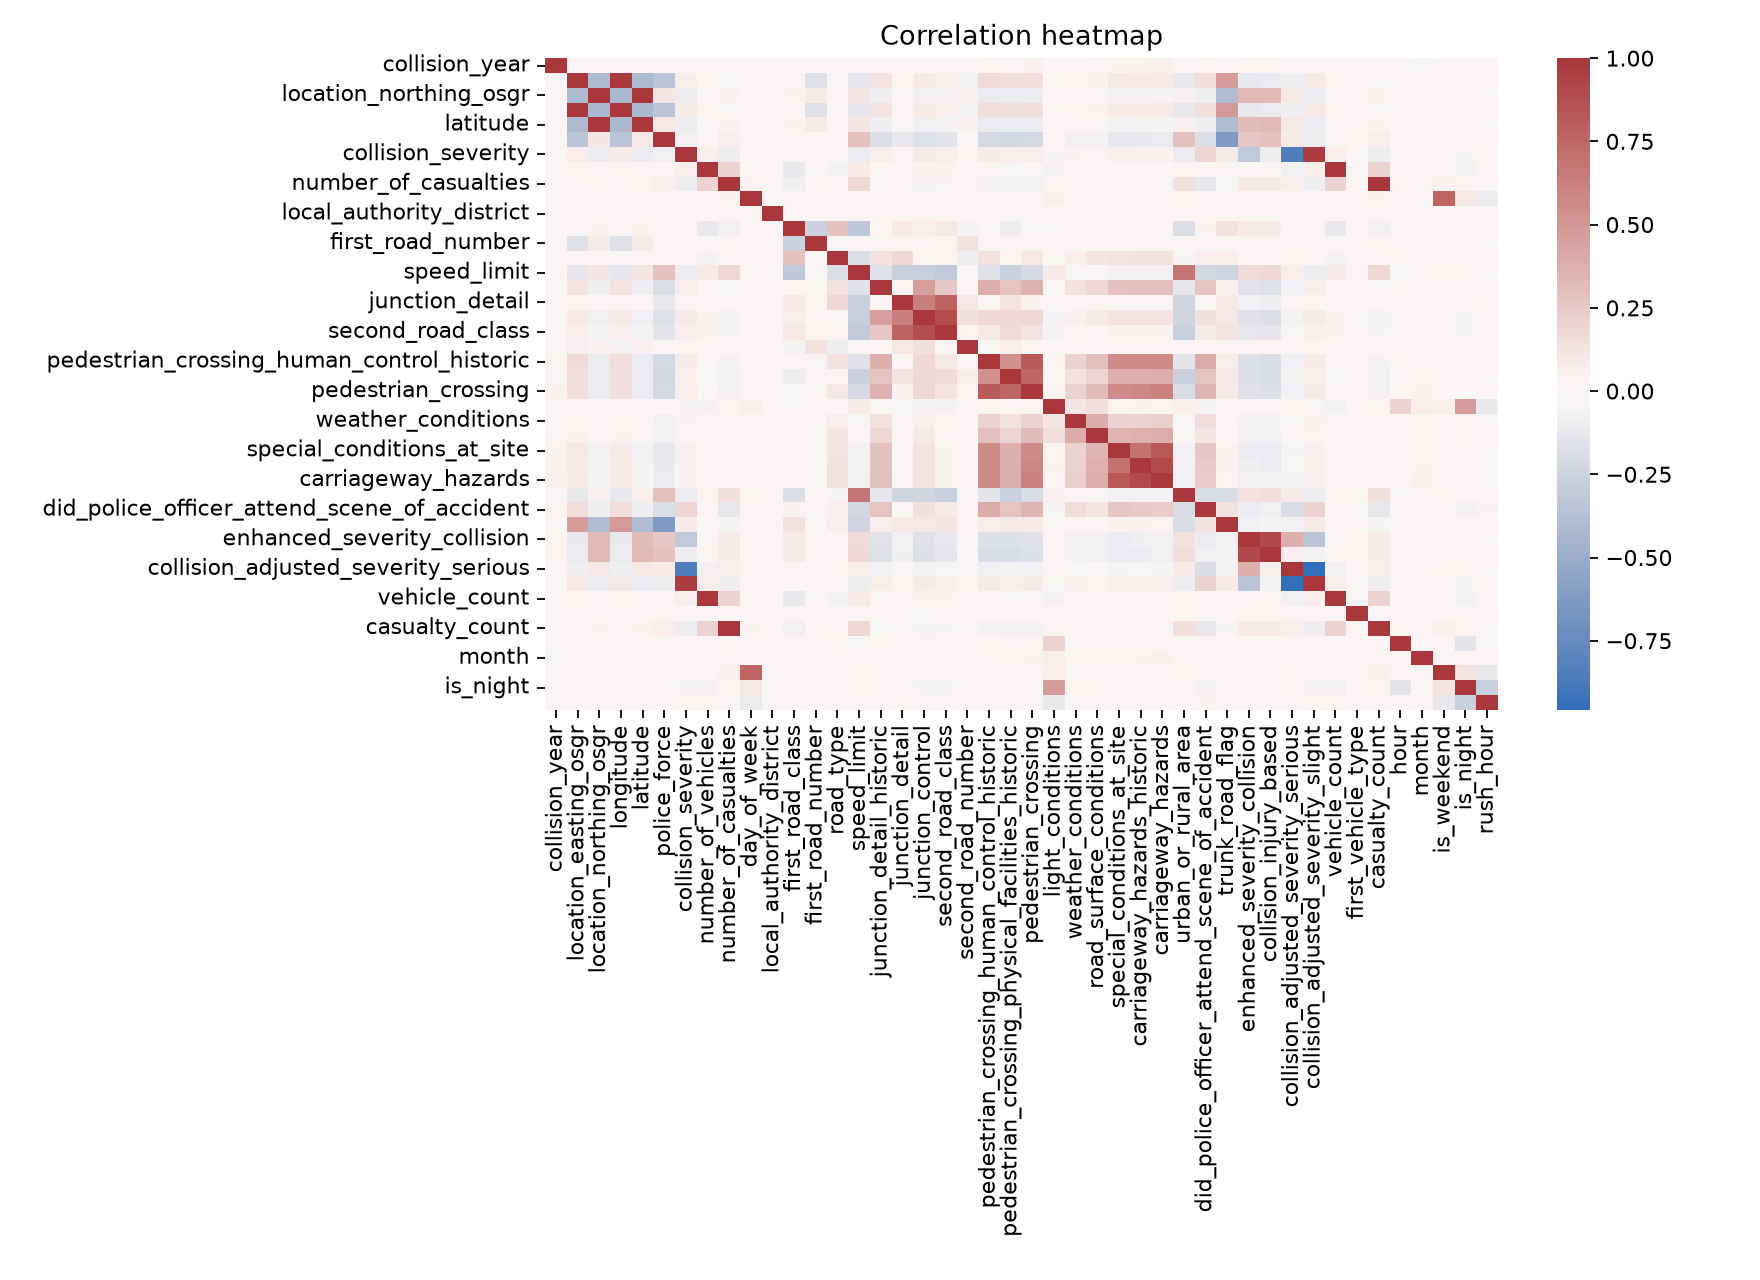

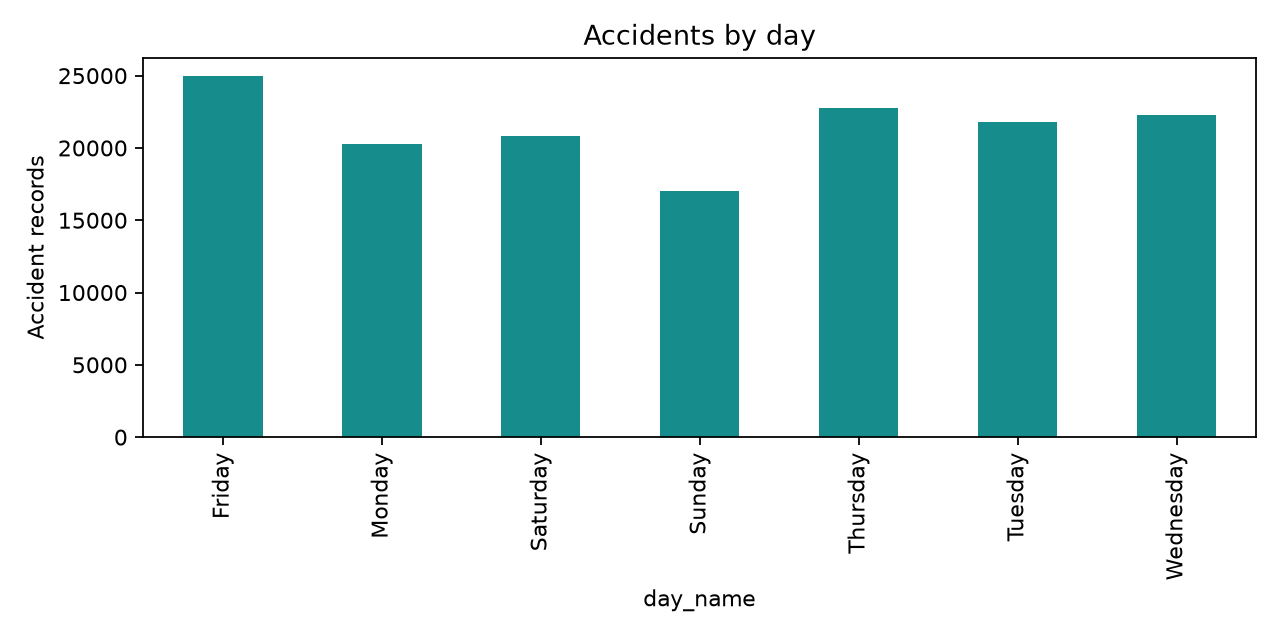

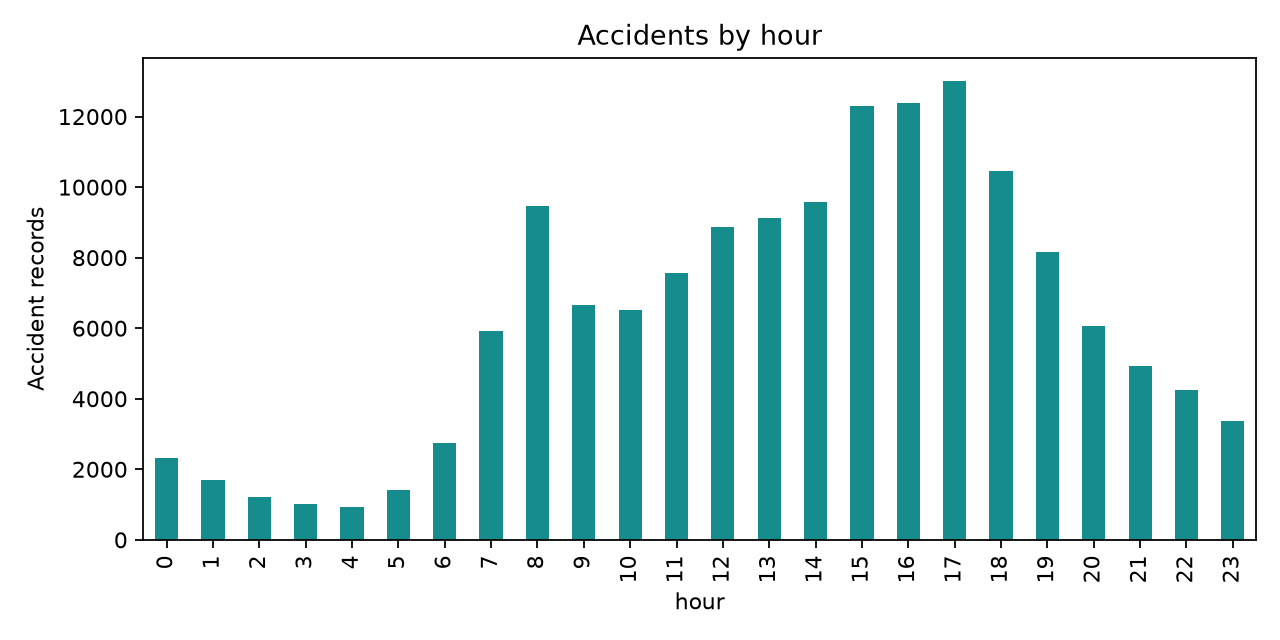

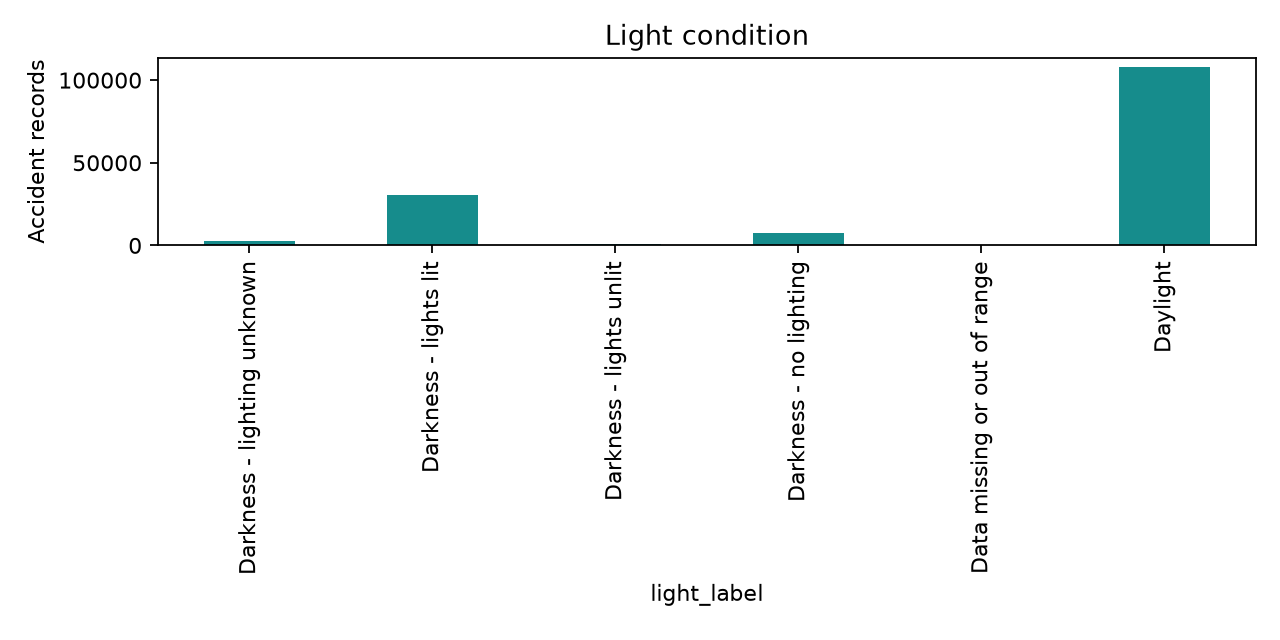

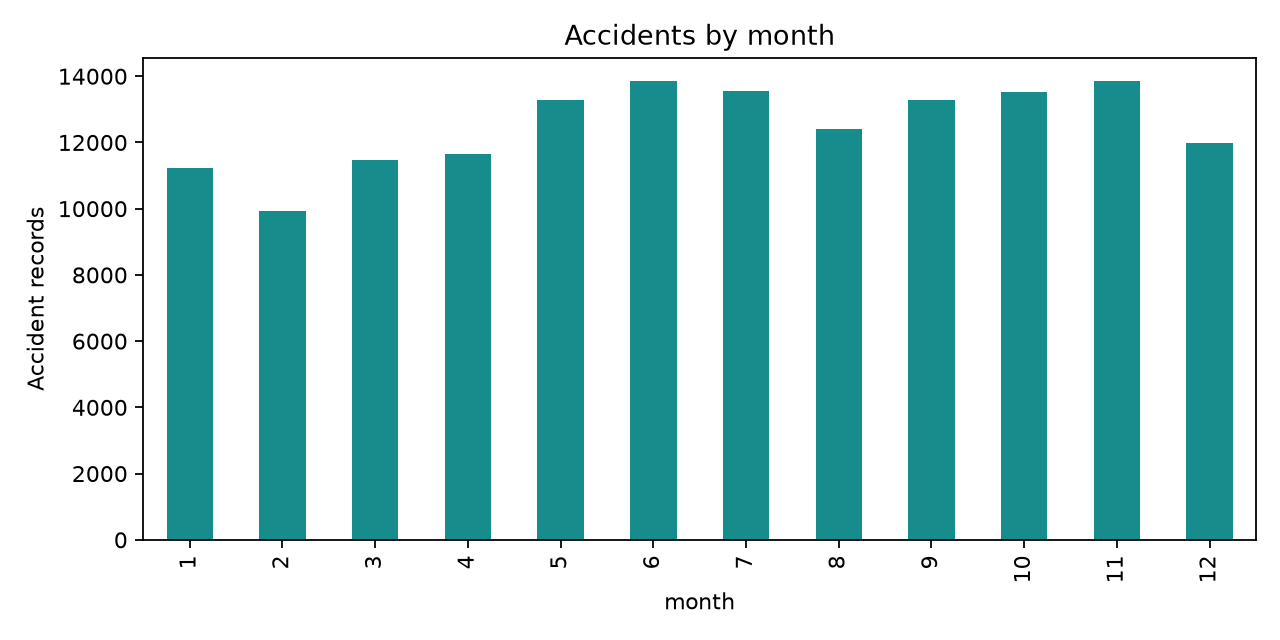

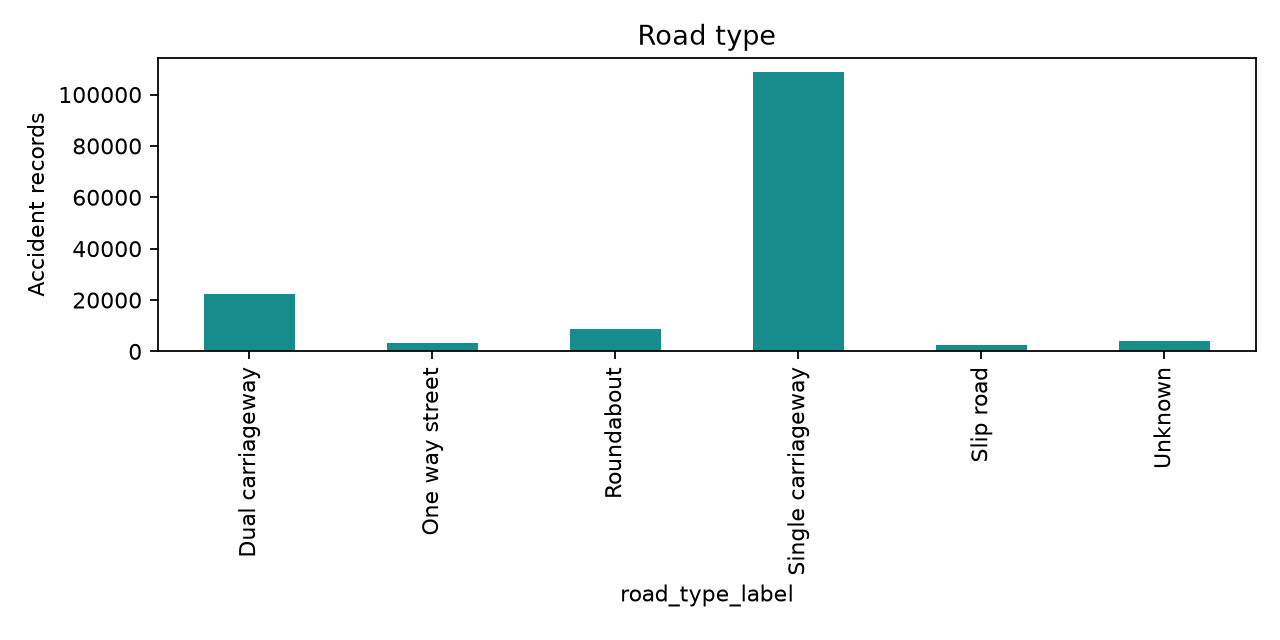

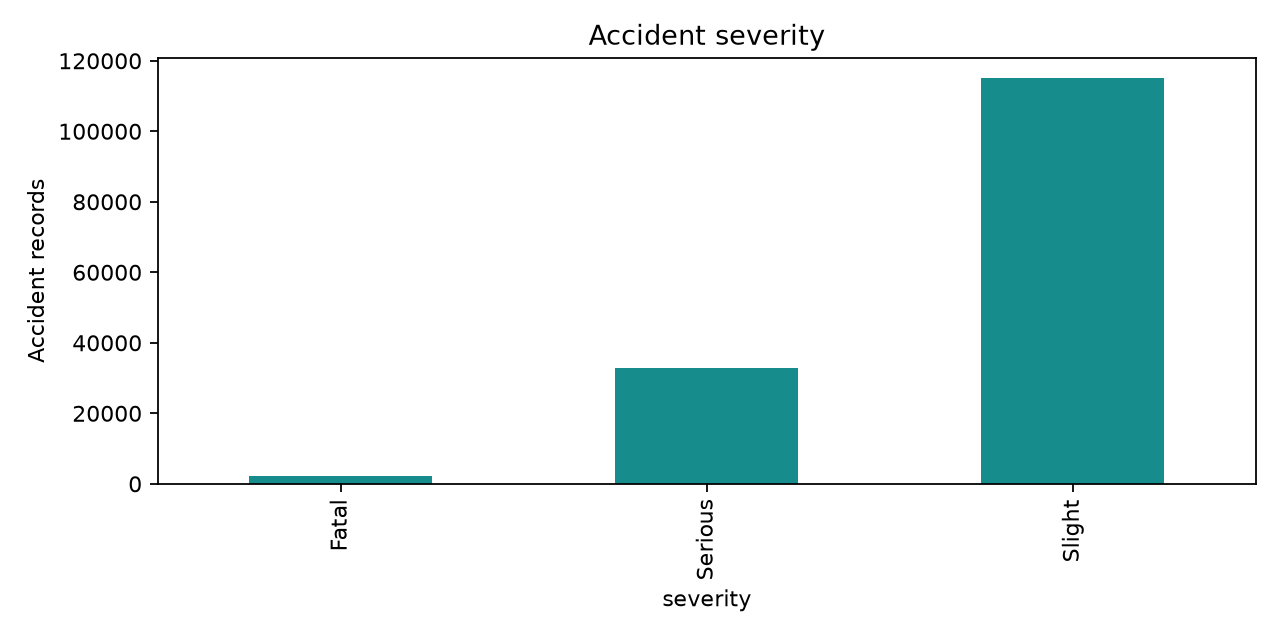

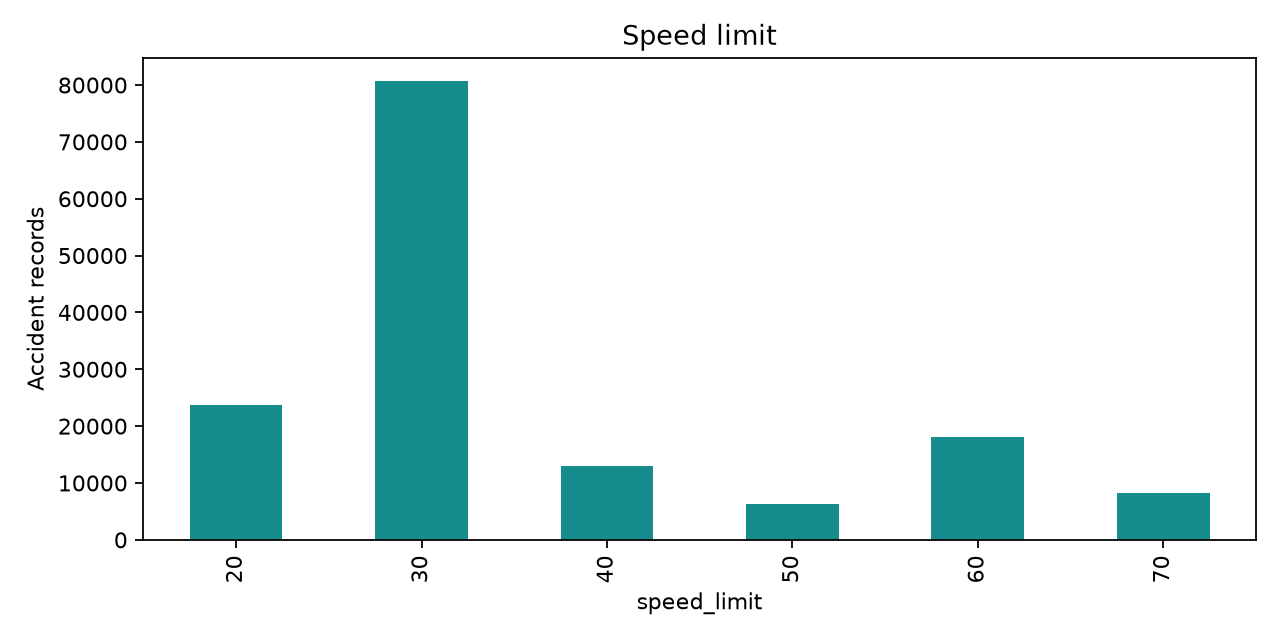

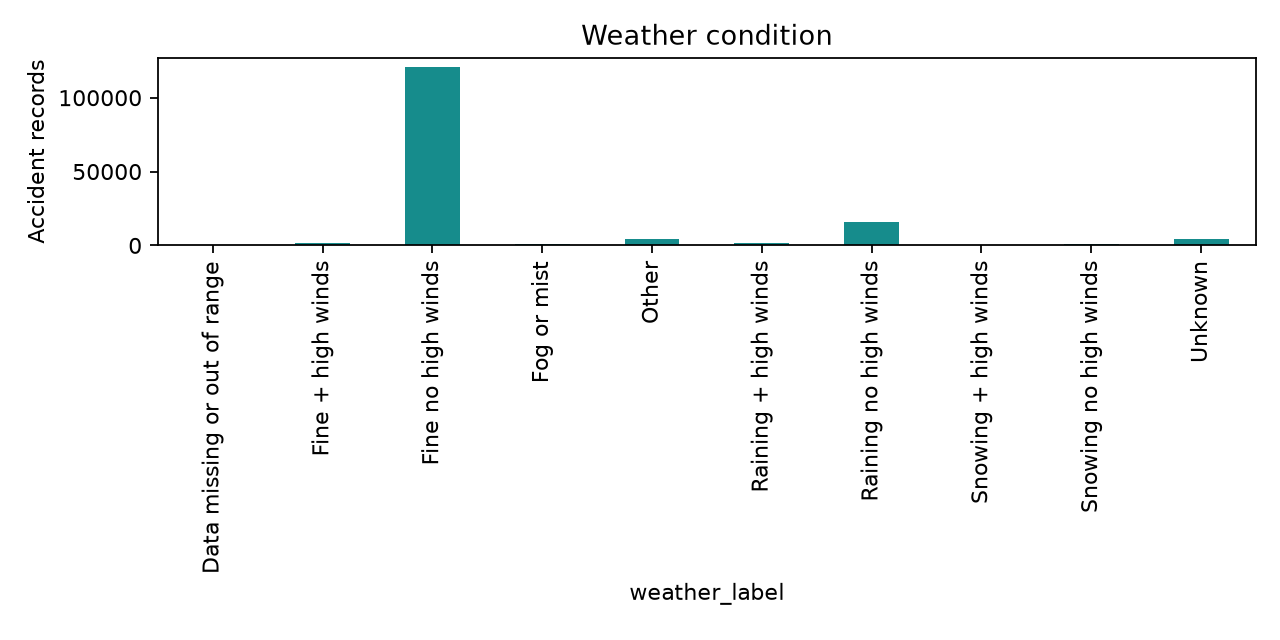

In [5]:
df['severity'] = df['collision_severity'].map({1:'Fatal',2:'Serious',3:'Slight'})
weather_names={1:'Fine no high winds',2:'Raining no high winds',3:'Snowing no high winds',4:'Fine + high winds',5:'Raining + high winds',6:'Snowing + high winds',7:'Fog or mist',8:'Other',9:'Unknown',-1:'Data missing or out of range'}
light_names={1:'Daylight',4:'Darkness - lights lit',5:'Darkness - lights unlit',6:'Darkness - no lighting',7:'Darkness - lighting unknown',-1:'Data missing or out of range'}
road_names={1:'Roundabout',2:'One way street',3:'Dual carriageway',6:'Single carriageway',7:'Slip road',9:'Unknown',12:'One way street/Slip road'}
surface_names={1:'Dry',2:'Wet or damp',3:'Snow',4:'Frost or ice',5:'Flood over 3cm deep',6:'Oil or diesel',7:'Mud',9:'Unknown (self reported)',-1:'Data missing or out of range'}
area_names={1:'Urban',2:'Rural',3:'Unallocated',-1:'Data missing or out of range'}
df['weather_label']=df.weather_conditions.map(weather_names).fillna('Unknown code')
df['light_label']=df.light_conditions.map(light_names).fillna('Unknown code')
df['road_type_label']=df.road_type.map(road_names).fillna('Unknown code')
df['surface_label']=df.road_surface_conditions.map(surface_names).fillna('Unknown code')
df['area_label']=df.urban_or_rural_area.map(area_names).fillna('Unknown code')
charts = {'severity':('severity','Accident severity'), 'hour':('hour','Accidents by hour'), 'day':('day_name','Accidents by day'), 'month':('month','Accidents by month'), 'weather':('weather_label','Weather condition'), 'road':('road_type_label','Road type'), 'speed':('speed_limit','Speed limit'), 'light':('light_label','Light condition')}
for name,(col,title) in charts.items():
    ax=df[col].value_counts().sort_index().plot(kind='bar', figsize=(8,4), title=title, color='#168c8c')
    ax.set_ylabel('Accident records'); plt.tight_layout(); plt.savefig(ROOT/f'outputs/figures/{name}_distribution.png',dpi=160); plt.close()
num=df.select_dtypes(include='number')
plt.figure(figsize=(11,8)); sns.heatmap(num.corr(), cmap='vlag', center=0); plt.title('Correlation heatmap'); plt.tight_layout(); plt.savefig(ROOT/'outputs/figures/correlation_heatmap.png',dpi=160); plt.close()
dictionary=pd.DataFrame({'column':['collision_index','severity','latitude','longitude','hour','month','day_of_week','day_name','is_weekend','is_night','rush_hour','season','weather_conditions','road_type','speed_limit','light_conditions','road_surface_conditions','urban_or_rural_area','weather_label','light_label','road_type_label','surface_label','area_label','vehicle_count','casualty_count','first_vehicle_type'], 'description':['Unique collision identifier','Target label: Fatal, Serious or Slight','Latitude','Longitude','Hour of collision','Month of collision','Day number, Monday=0','Day name','Binary weekend indicator','Binary night indicator','Binary peak commute indicator','Meteorological season','DfT weather code','DfT road type code','Road speed limit in mph','DfT light condition code','DfT road surface code','DfT urban/rural code','Readable weather label','Readable light condition label','Readable road type label','Readable road surface label','Readable urban or rural label','Vehicles recorded in collision','Casualties recorded in collision','DfT vehicle type code of primary involved vehicle']})
dictionary.to_csv(ROOT/'data/processed/data_dictionary.csv',index=False)
print('What we found:')
print(df['severity'].value_counts(normalize=True).round(3))
print('Rows:',len(df),' years:',sorted(df.collision_year.unique()))
print('Median accidents per hour:',df.groupby('hour').size().median())
print('Fatal share:',round((df.severity=='Fatal').mean()*100,3),'percent')

df.to_csv(ROOT/'data/processed/cleaned_accidents.csv', index=False)
